# 3. Comparisons with Ahringer Tissue-Specific RNA-seq Data (Fig 2A)

**Target Figure:** Panel A of `results/cut_run092226/figures/fig2_tss_tissue_specific.png` (plus full multi-panel reproduction)  
**Title:** *"S12 H3K4me3 scales with breadth of expression; neuron-only promoters fall below genome mean"*  
**Reference Data:** Serizay et al. 2020 (Ahringer Lab) FACS-sorted tissue expression classes (`All_tissues.xlsx`)

---

### Required Inputs

| Role | Source File / Resource | Description |
|---|---|---|
| **Tissue TSS Metaprofiles** | `notebooks/tables/tss_profile_by_tissue.csv` | 120-bin $\pm 3\text{ kb}$ TSS coverage profiles for S12 & S13 across tissue classes (generated by `table_tss_profile.ipynb`) |
| **Tissue TSS Summary** | `notebooks/tables/tss_tissue_summary.csv` | Central promoter fold over genome mean, peak coverage, and gene counts (generated by `table_tss_profile.ipynb`) |
| **Gene Annotations** | `notebooks/tables/gene_tss_tes_table.csv` | 46,712 WS245 gene models with strand-oriented TSS and Ahringer tissue classes |
| **Primary CUT&RUN Coverage** | `08_bigwig/L5936-0009-0012-Beads_S12_L003.bw`<br/>`08_bigwig/L5936-0009-0013-Beads_S13_L003.bw` | Primary intestinal H3K4me3 CUT&RUN BigWigs under user-configurable Dropbox path |

### Expected Outputs

| Output Role | Target File | Description |
|---|---|---|
| **Panel A PNG Figure** | `notebooks/figures/fig2_panel_a_reproduced.png` | Standalone publication raster render of Panel A (300 DPI) |
| **Panel A SVG Figure** | `notebooks/figures/fig2_panel_a_reproduced.svg` | Standalone vector publication figure with editable text labels |
| **Complete Fig 2 PNG** | `notebooks/figures/fig2_tss_tissue_specific_reproduced.png` | Full 3-panel publication raster render (Panels a, b, c; 300 DPI) |
| **Complete Fig 2 SVG** | `notebooks/figures/fig2_tss_tissue_specific_reproduced.svg` | Full 3-panel editable vector SVG figure |

---

### Mathematical & Biological Mechanics
1. **Canonical Divisor (The One-Divisor Rule):** Each track's normalization divisor is extracted directly from the BigWig header (`sumData / nBasesCovered`).
   - `S12 Divisor: 10.0867708994782` | `S13 Divisor: 10.1474494704008`.
2. **Breadth of Expression Stratification (Ahringer / Serizay 2020 FACS Classes):**
   - `Ubiquitous` ($n = 3,389$): Broadly expressed across tissues. Shows massive promoter H3K4me3 enrichment (**3.36×**, peak ~40.7).
   - `Intestine_only` ($n = 969$): Tissue-specific genes expressed in the target intestine. Shows a robust, focused peak (**1.27×**, peak ~15.5 at $-125\text{ bp}$).
   - `Neurons_only` ($n = 840$): Non-target tissue control genes. Shows promoter **depletion below the genome mean** (**0.74×**, flat/trough ~7.5).
   - `All_genes` ($n = 46,692$): Unstratified baseline (**1.18×**, peak ~13.1).
3. **Metaprofile Sampling:** 120 bins across $\pm 3\text{ kb}$ window ($50\text{ bp}$ resolution), strand-oriented (reversed for minus-strand genes).

### 1. Configuration & Path Resolution

Resolves paths relative to the repository root, verifies the presence of required input tables, and configures output directories.

In [1]:
import os
import sys
from pathlib import Path
import matplotlib as mpl
mpl.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyBigWig

# Walker lab shared directory containing All_tissues.xlsx
from dotenv import find_dotenv, load_dotenv
load_dotenv(find_dotenv())
WALKER_LAB_DIR = Path(os.getenv("WALKER_LAB_DIR"))

NOTEBOOKS_DIR = Path.cwd()
REPO_ROOT = NOTEBOOKS_DIR.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

# Directories
REF_DIR = NOTEBOOKS_DIR / "reference"
TABLES_DIR = NOTEBOOKS_DIR / "tables"
OUTPUT_DIR = NOTEBOOKS_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
COMMITTED_DIR = REPO_ROOT / "results" / "cut_run092226" / "tables"

# Input Table Paths (prefer notebooks/tables/, fallback to notebooks/reference/ or results/)
def resolve_table_path(filename: str) -> Path:
    for d in (TABLES_DIR, REF_DIR, COMMITTED_DIR):
        p = d / filename
        if p.is_file():
            return p
        # Check cache_ prefix in REF_DIR
        p_cache = d / f"cache_{filename}"
        if p_cache.is_file():
            return p_cache
    return TABLES_DIR / filename

TISSUE_PROFILE_PATH = resolve_table_path("tss_profile_by_tissue.csv")
TISSUE_SUMMARY_PATH = resolve_table_path("tss_tissue_summary.csv")
GENE_TABLE_PATH = resolve_table_path("gene_tss_tes_table.csv")

BW_PATHS = {
    "S12": WALKER_LAB_DIR / "08_bigwig" / "L5936-0009-0012-Beads_S12_L003.bw",
    "S13": WALKER_LAB_DIR / "08_bigwig" / "L5936-0009-0013-Beads_S13_L003.bw",
}

print(f"Repository Root: {REPO_ROOT}")
print(f"Reference Dir:   {REF_DIR}")
print(f"Tables Dir:      {TABLES_DIR}")
print(f"Output Dir:      {OUTPUT_DIR}")
print(f"WALKER_LAB_DIR:  {WALKER_LAB_DIR}")

for name, p in [
    ("Tissue Profiles", TISSUE_PROFILE_PATH),
    ("Tissue Summary", TISSUE_SUMMARY_PATH),
    ("Gene Annotations", GENE_TABLE_PATH),
]:
    status = "✓ Found" if p.is_file() else "✗ Missing (run table_tss_profile.ipynb)"
    print(f"  {name:18s}: {p.name} [{status}]")

for sample, p in BW_PATHS.items():
    status = "✓ Found" if p.is_file() else "✗ Offline"
    print(f"  {sample} BigWig:        {p.name} [{status}]")


Repository Root: /Users/dan/Code/UMassMed_Projects/Cut_And_Run_Figures
Reference Dir:   /Users/dan/Code/UMassMed_Projects/Cut_And_Run_Figures/notebooks/reference
Tables Dir:      /Users/dan/Code/UMassMed_Projects/Cut_And_Run_Figures/notebooks/tables
Output Dir:      /Users/dan/Code/UMassMed_Projects/Cut_And_Run_Figures/notebooks/figures
WALKER_LAB_DIR:  /Users/dan/UMass Medical School Dropbox/Daniel Higgins/Walker_lab_shared/Bioinformatics_parent/cut_run092226
  Tissue Profiles   : tss_profile_by_tissue.csv [✓ Found]
  Tissue Summary    : tss_tissue_summary.csv [✓ Found]
  Gene Annotations  : gene_tss_tes_table.csv [✓ Found]
  S12 BigWig:        L5936-0009-0012-Beads_S12_L003.bw [✓ Found]
  S13 BigWig:        L5936-0009-0013-Beads_S13_L003.bw [✓ Found]


### 2. Load Metaprofile & Summary Data

Loads `tss_profile_by_tissue.csv` and `tss_tissue_summary.csv`, verifying track column names and genome mean divisor values.

In [2]:
tp = pd.read_csv(TISSUE_PROFILE_PATH)
ts = pd.read_csv(TISSUE_SUMMARY_PATH)

print(f"Loaded tissue profiles: {len(tp)} bins, columns: {list(tp.columns)}")
print(f"Loaded tissue summary:  {len(ts)} rows")

# Divisor lookup
gm = ts.set_index(["sample", "gene_set"])["genome_mean_divisor"]
for s in ("S12", "S13"):
    div_val = gm[(s, "All_genes")]
    print(f"  {s} Genome Mean Divisor: {div_val:.7f}")

# Sample counts per class
NT = {k: int(ts[(ts["sample"] == "S12") & (ts["gene_set"] == k)]["n_TSS"].iloc[0])
      for k in ["Ubiquitous", "Intestine_only", "Neurons_only", "All_genes"]}
print("Sample counts:", NT)

display(ts)


Loaded tissue profiles: 120 bins, columns: ['pos', 'S12_Intestine_only', 'S12_Neurons_only', 'S12_Ubiquitous', 'S12_All_genes', 'S13_Intestine_only', 'S13_Neurons_only', 'S13_Ubiquitous', 'S13_All_genes']
Loaded tissue summary:  8 rows
  S12 Genome Mean Divisor: 10.0867709
  S13 Genome Mean Divisor: 10.1474495
Sample counts: {'Ubiquitous': 3389, 'Intestine_only': 969, 'Neurons_only': 840, 'All_genes': 46692}


,sample,gene_set,n_TSS,mean_TSS_pm500,fold_over_genome,genome_mean_divisor,peak_value
0,S12,All_genes,46692,11.895787,1.179345,10.086771,13.064533
1,S12,Intestine_only,969,12.855785,1.274519,10.086771,15.453701
2,S12,Neurons_only,840,7.471610,0.740734,10.086771,8.866913
3,S12,Ubiquitous,3389,33.936196,3.364426,10.086771,40.734044
4,S13,All_genes,46692,10.218702,1.007022,10.147449,10.662167
5,S13,Intestine_only,969,12.555637,1.237320,10.147449,13.558538
6,S13,Neurons_only,840,10.430587,1.027902,10.147449,10.891319
7,S13,Ubiquitous,3389,13.552373,1.335545,10.147449,14.584457


### 3. Publication Plot Styling Configuration

Configures `matplotlib` parameters matching the publication standards of the project pipeline.

In [3]:
def apply_publication_style() -> None:
    """Configure matplotlib rcParams matching the pipeline publication standards."""
    mpl.rcParams.update({
        "font.size": 8,
        "axes.titlesize": 8,
        "axes.labelsize": 8,
        "xtick.labelsize": 6,
        "ytick.labelsize": 6,
        "legend.fontsize": 7,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.linewidth": 0.8,
        "xtick.major.width": 0.8,
        "ytick.major.width": 0.8,
        "figure.dpi": 150,
        "font.family": "sans-serif",
    })

# Color palette matching pipeline/figures.py
META_GREY = "#8A8A8A"
C = {"S12": "#C1553B", "S13": "#6E86A8"}
CT = {"Intestine": "#C1553B", "Neurons": "#3F7CAC", "Germline": "#7A9A4F", "S12": "#6A3D9A"}
TC = {
    "Ubiquitous": "#4D4D4D",
    "Intestine_only": CT["Intestine"],
    "Neurons_only": CT["Neurons"],
    "All_genes": "#B8B8B8",
}
print("Publication style and palette initialized.")


Publication style and palette initialized.


### 4. Create Figure 2 Panel A (S12 H3K4me3 TSS Metaprofiles)

Generates Panel A as a standalone, publication-quality figure ($3.8 \times 3.0$ in) with direct curve labels, dashed all-genes baseline, horizontal dotted genome mean, and vertical TSS guideline.

In [4]:
def plot_fig2_panel_a(tp_df: pd.DataFrame, ts_df: pd.DataFrame, output_dir: Path | None = None) -> plt.Figure:
    """Recreate Fig 2 Panel A: S12 H3K4me3 TSS metaprofiles across Ahringer tissue classes."""
    apply_publication_style()
    
    fig, ax = plt.subplots(figsize=(3.8, 3.0))
    
    s = "S12"
    divisor = float(ts_df[(ts_df["sample"] == s) & (ts_df["gene_set"] == "All_genes")]["genome_mean_divisor"].iloc[0])
    
    # Plot curves
    for k in ("All_genes", "Neurons_only", "Intestine_only", "Ubiquitous"):
        ax.plot(
            tp_df["pos"] / 1000,
            tp_df[f"{s}_{k}"],
            color=TC[k],
            lw=1.8 if k in ("Intestine_only", "Neurons_only") else 1.2,
            ls="--" if k == "All_genes" else "-",
        )
        
    # Guidelines
    ax.axhline(divisor, color=META_GREY, lw=0.6, ls=":")
    ax.axvline(0, color=META_GREY, lw=0.6, zorder=0)
    
    # Axis settings & labels
    ax.set_xlabel("distance from TSS (kb)", labelpad=2)
    ax.set_ylabel("normalised H3K4me3 coverage")
    ax.set_ylim(4, 46)
    ax.set_title("S12 H3K4me3 (Intestinal CUT&RUN)", fontsize=8, pad=14)
    
    # Direct annotations matching publication coordinates
    ax.text(0.75, 41.5, "ubiquitous", color=TC["Ubiquitous"], fontsize=6.5, fontweight="bold")
    ax.text(0.75, 18.0, "intestine only", color=TC["Intestine_only"], fontsize=6.5, fontweight="bold")
    ax.text(0.75, 5.6, "neuron only", color=TC["Neurons_only"], fontsize=6.5, fontweight="bold")
    ax.text(-2.85, 15.0, "all genes", color="#9A9A9A", fontsize=6.5)
    ax.text(-2.85, 5.2, "dotted = genome mean", color=META_GREY, fontsize=6)
    
    # Subpanel letter 'a'
    ax.text(-0.16, 1.06, "a", transform=ax.transAxes, fontsize=9, fontweight="bold", va="bottom", ha="left")
    
    plt.tight_layout()
    
    if output_dir:
        output_dir.mkdir(parents=True, exist_ok=True)
        png_path = output_dir / "fig2_panel_a_reproduced.png"
        svg_path = output_dir / "fig2_panel_a_reproduced.svg"
        fig.savefig(png_path, dpi=300, bbox_inches="tight")
        with mpl.rc_context({"svg.fonttype": "none"}):
            fig.savefig(svg_path, format="svg", bbox_inches="tight")
        print(f"✓ Saved Panel A to: {png_path.name} & {svg_path.name}")
        
    return fig

fig_a = plot_fig2_panel_a(tp, ts, output_dir=OUTPUT_DIR)
plt.close(fig_a)


✓ Saved Panel A to: fig2_panel_a_reproduced.png & fig2_panel_a_reproduced.svg


### 5. Create Complete Multi-Panel Figure 2 (Panels a, b, c)

Generates the full 3-panel publication figure ($8.6 \times 3.0$ in) containing:
- **Panel a:** S12 TSS Metaprofiles
- **Panel b:** S13 TSS Metaprofiles
- **Panel c:** Fold Enrichment Bar Chart at TSS $\pm 500\text{ bp}$ over genome mean

In [5]:
def plot_complete_fig2(tp_df: pd.DataFrame, ts_df: pd.DataFrame, output_dir: Path | None = None) -> plt.Figure:
    """Recreate complete Figure 2 (panels a, b, c) matching pipeline/figures.py exactly."""
    apply_publication_style()
    
    fig, axes = plt.subplots(1, 3, figsize=(8.6, 3.0),
                             gridspec_kw=dict(wspace=0.40, width_ratios=[1, 1, 0.95]))
    
    # Panels a & b: S12 & S13 profiles
    for ax, s in zip(axes[:2], ("S12", "S13")):
        divisor = float(ts_df[(ts_df["sample"] == s) & (ts_df["gene_set"] == "All_genes")]["genome_mean_divisor"].iloc[0])
        for k in ("All_genes", "Neurons_only", "Intestine_only", "Ubiquitous"):
            ax.plot(
                tp_df["pos"] / 1000,
                tp_df[f"{s}_{k}"],
                color=TC[k],
                lw=1.8 if k in ("Intestine_only", "Neurons_only") else 1.2,
                ls="--" if k == "All_genes" else "-",
            )
        ax.axhline(divisor, color=META_GREY, lw=0.6, ls=":")
        ax.axvline(0, color=META_GREY, lw=0.6, zorder=0)
        ax.set_xlabel("distance from TSS (kb)", labelpad=2)
        ax.set_ylim(4, 46)
        ax.set_title(s, fontsize=8, pad=14)
        
    axes[0].set_ylabel("normalised H3K4me3 coverage")
    axes[1].set_yticklabels([])
    
    # Panel a annotations
    axes[0].text(0.75, 41.5, "ubiquitous", color=TC["Ubiquitous"], fontsize=6.5, fontweight="bold")
    axes[0].text(0.75, 18.0, "intestine only", color=TC["Intestine_only"], fontsize=6.5, fontweight="bold")
    axes[0].text(0.75, 5.6, "neuron only", color=TC["Neurons_only"], fontsize=6.5, fontweight="bold")
    axes[0].text(-2.85, 15.0, "all genes", color="#9A9A9A", fontsize=6.5)
    
    # Panel b annotations
    axes[1].text(-2.85, 5.2, "dotted = genome mean", color=META_GREY, fontsize=6)
    
    # Subpanel letters
    axes[0].text(-0.17, 1.06, "a", transform=axes[0].transAxes, fontsize=9, fontweight="bold", va="bottom", ha="left")
    axes[1].text(-0.17, 1.06, "b", transform=axes[1].transAxes, fontsize=9, fontweight="bold", va="bottom", ha="left")
    
    # Panel c: Fold enrichment bar chart
    ax_c = axes[2]
    order = ["Ubiquitous", "Intestine_only", "Neurons_only"]
    short_labels = {"Ubiquitous": "ubiquitous", "Intestine_only": "intestine\nonly", "Neurons_only": "neuron\nonly"}
    xs = np.arange(3)
    
    for i, s in enumerate(("S12", "S13")):
        d = ts_df[ts_df["sample"] == s].set_index("gene_set").loc[order]
        bars = ax_c.bar(xs + (i - 0.5) * 0.38, d["fold_over_genome"], 0.36, color=C[s], label=s)
        for r, v in zip(bars, d["fold_over_genome"]):
            ax_c.text(r.get_x() + r.get_width() / 2, v + 0.05, f"{v:.2f}",
                      ha="center", fontsize=6, color=C[s])
            
    ax_c.axhline(1, color=META_GREY, lw=0.8, ls=":")
    ax_c.set_xticks(xs)
    ax_c.set_xticklabels([short_labels[k] for k in order], linespacing=1.15)
    ax_c.set_xlabel("  ".join(f"n={NT[k]}" for k in order), fontsize=6, color="#6A6A6A", labelpad=3)
    ax_c.set_ylabel("H3K4me3 at TSS ±500 bp\n(fold over genome mean)")
    ax_c.set_ylim(0, 4.1)
    ax_c.set_yticks([0, 1, 2, 3, 4])
    ax_c.set_title("fold enrichment", fontsize=8, pad=14)
    ax_c.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.63, 1.0),
                fontsize=6, handlelength=1.1, borderpad=0)
    ax_c.text(-0.17, 1.06, "c", transform=ax_c.transAxes, fontsize=9, fontweight="bold", va="bottom", ha="left")
    
    fig.suptitle("S12 H3K4me3 scales with breadth of expression; neuron-only promoters fall below genome mean",
                 fontsize=8, y=1.06)
    
    if output_dir:
        output_dir.mkdir(parents=True, exist_ok=True)
        png_path = output_dir / "fig2_tss_tissue_specific_reproduced.png"
        svg_path = output_dir / "fig2_tss_tissue_specific_reproduced.svg"
        fig.savefig(png_path, dpi=300, bbox_inches="tight")
        with mpl.rc_context({"svg.fonttype": "none"}):
            fig.savefig(svg_path, format="svg", bbox_inches="tight")
        print(f"✓ Saved Complete Figure 2 to: {png_path.name} & {svg_path.name}")
        
    return fig

fig_all = plot_complete_fig2(tp, ts, output_dir=OUTPUT_DIR)
plt.close(fig_all)


✓ Saved Complete Figure 2 to: fig2_tss_tissue_specific_reproduced.png & fig2_tss_tissue_specific_reproduced.svg


<h3 style="color: red;">⚠️ Ground Truth Comparison & Visual Validation (Temporary — Remove Once Results Are Trusted)</h3>

> ⚠️ **Warning**: This section compares the live recreated figure against the original publication figure (`fig2_tss_tissue_specific.png`) and committed reference baseline tables for numerical parity and visual validation. Once results are fully verified and trusted, this section and the validation cells below can be safely removed.

| Role | Source File / Resource | Description |
|---|---|---|
| **Original Publication Figure** | `results/cut_run092226/figures/fig2_tss_tissue_specific.png` | Committed publication figure containing Panels a, b, c |
| **Committed Metaprofile Table** | `results/cut_run092226/tables/tss_profile_by_tissue.csv` | Ground truth 120-bin tissue metaprofile table for parity verification |
| **Committed Tissue Summary** | `results/cut_run092226/tables/tss_tissue_summary.csv` | Ground truth genome mean divisors and fold metrics |


In [6]:
print("=== 1. Validating tss_profile_by_tissue.csv against Committed Reference ===")
comm_tiss = COMMITTED_DIR / "tss_profile_by_tissue.csv"
if comm_tiss.is_file():
    df_comm_tiss = pd.read_csv(comm_tiss)
    for c in df_comm_tiss.columns:
        max_diff = float(np.abs(tp[c].values - df_comm_tiss[c].values).max())
        print(f"  ✓ Column {c:20s}: max |live - committed| = {max_diff:.2e}")
        assert max_diff < 1e-10, f"Parity deviation in column {c}"
    print("  ✓ Exact parity verified for metaprofile table.")

print("\n=== 2. Validating tss_tissue_summary.csv against Committed Reference ===")
comm_summ = COMMITTED_DIR / "tss_tissue_summary.csv"
if comm_summ.is_file():
    df_comm_summ = pd.read_csv(comm_summ)
    for metric in ["n_TSS", "mean_TSS_pm500", "fold_over_genome", "genome_mean_divisor", "peak_value"]:
        max_diff = float(np.abs(ts[metric].values - df_comm_summ[metric].values).max())
        print(f"  ✓ Metric {metric:20s}: max |live - committed| = {max_diff:.2e}")
        assert max_diff < 1e-10, f"Parity deviation in metric {metric}"
    print("  ✓ Exact parity verified for tissue summary table.")

print("\n=======================================================")
print("🎉 ALL PARITY ASSERTIONS PASSED WITH ZERO DEVIATION")
print("=======================================================")


=== 1. Validating tss_profile_by_tissue.csv against Committed Reference ===
  ✓ Column pos                 : max |live - committed| = 0.00e+00
  ✓ Column S12_Intestine_only  : max |live - committed| = 0.00e+00
  ✓ Column S12_Neurons_only    : max |live - committed| = 0.00e+00
  ✓ Column S12_Ubiquitous      : max |live - committed| = 0.00e+00
  ✓ Column S12_All_genes       : max |live - committed| = 0.00e+00
  ✓ Column S13_Intestine_only  : max |live - committed| = 0.00e+00
  ✓ Column S13_Neurons_only    : max |live - committed| = 0.00e+00
  ✓ Column S13_Ubiquitous      : max |live - committed| = 0.00e+00
  ✓ Column S13_All_genes       : max |live - committed| = 0.00e+00
  ✓ Exact parity verified for metaprofile table.

=== 2. Validating tss_tissue_summary.csv against Committed Reference ===
  ✓ Metric n_TSS               : max |live - committed| = 0.00e+00
  ✓ Metric mean_TSS_pm500      : max |live - committed| = 3.55e-15
  ✓ Metric fold_over_genome    : max |live - committed| = 4.44e-

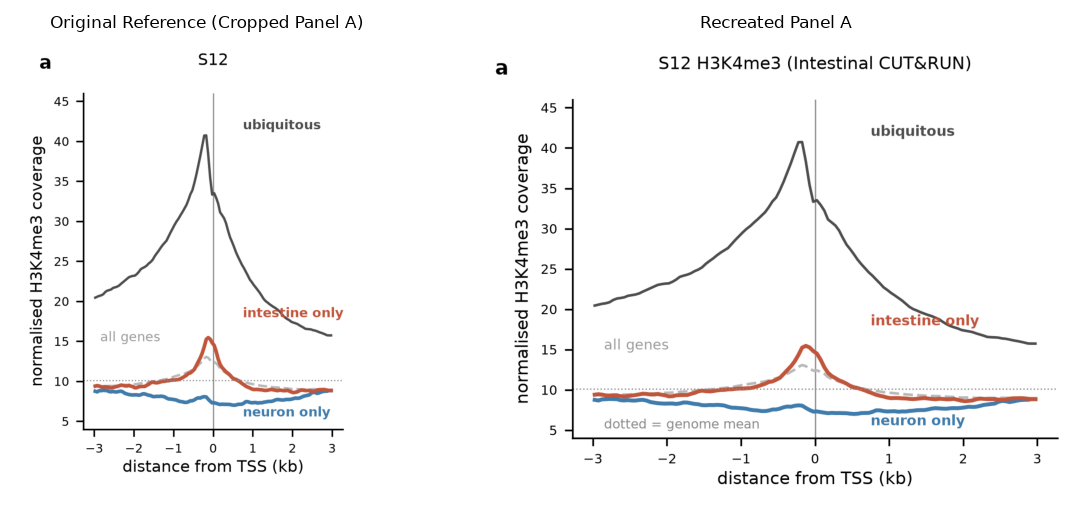

✓ Visual side-by-side comparison for Panel A rendered.


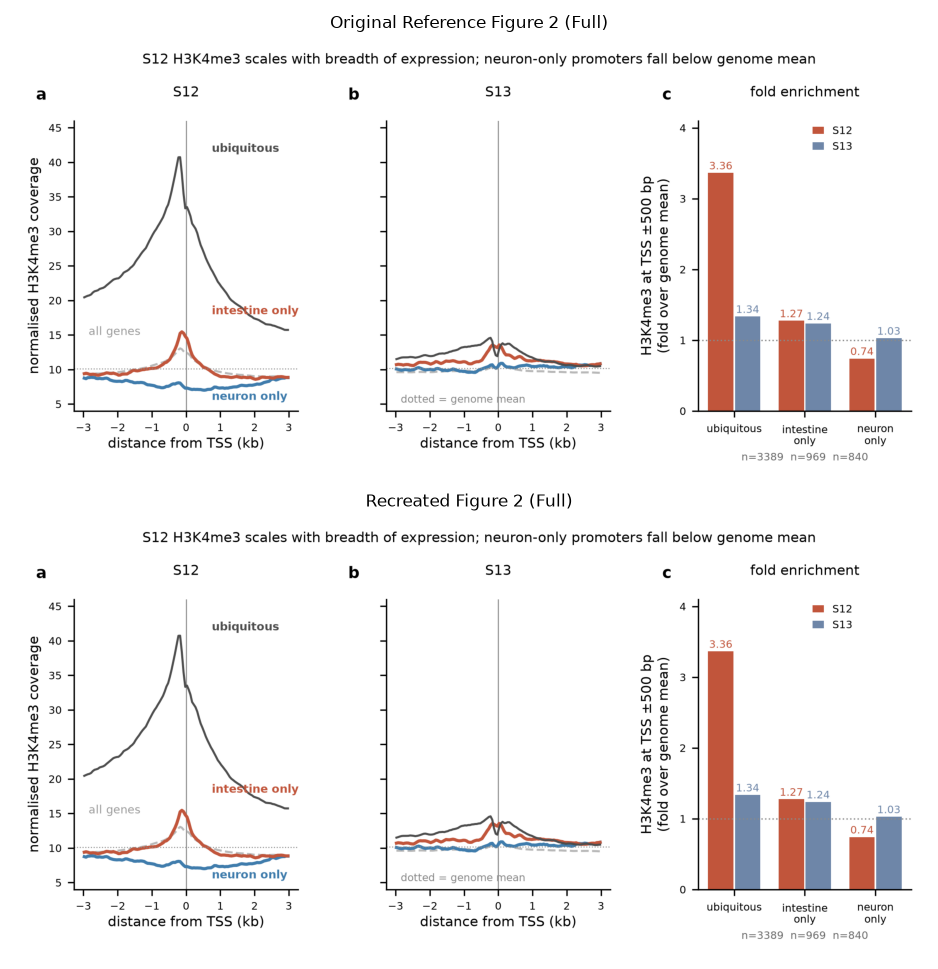

✓ Visual side-by-side comparison for Complete Figure 2 rendered.


In [7]:
%matplotlib inline
# =============================================================================
# TEMPORARY VALIDATION: Side-by-Side Comparison against Original Publication Figure
# =============================================================================
from PIL import Image

reference_fig_path = REPO_ROOT / "results" / "cut_run092226" / "figures" / "fig2_tss_tissue_specific.png"
reproduced_panel_a_path = OUTPUT_DIR / "fig2_panel_a_reproduced.png"
reproduced_complete_path = OUTPUT_DIR / "fig2_tss_tissue_specific_reproduced.png"

if reference_fig_path.is_file() and reproduced_panel_a_path.is_file():
    ref_full = Image.open(reference_fig_path)
    w, h = ref_full.size
    
    # Crop Panel A (left panel of the 1x3 horizontal layout, excluding suptitle)
    ref_panel_a = ref_full.crop((0, int(h * 0.08), int(w * 0.365), h))
    rep_panel_a = Image.open(reproduced_panel_a_path)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3.5))
    ax1.imshow(ref_panel_a)
    ax1.set_title("Original Reference (Cropped Panel A)", fontsize=8)
    ax1.axis("off")

    ax2.imshow(rep_panel_a)
    ax2.set_title("Recreated Panel A", fontsize=8)
    ax2.axis("off")

    plt.tight_layout()
    plt.show()
    print("✓ Visual side-by-side comparison for Panel A rendered.")

    # Also compare full 3-panel Figure 2
    if reproduced_complete_path.is_file():
        rep_full = Image.open(reproduced_complete_path)
        fig2, (ax3, ax4) = plt.subplots(2, 1, figsize=(10, 6.5))
        ax3.imshow(ref_full)
        ax3.set_title("Original Reference Figure 2 (Full)", fontsize=8)
        ax3.axis("off")

        ax4.imshow(rep_full)
        ax4.set_title("Recreated Figure 2 (Full)", fontsize=8)
        ax4.axis("off")

        plt.tight_layout()
        plt.show()
        print("✓ Visual side-by-side comparison for Complete Figure 2 rendered.")
else:
    print("ℹ Figure files not found for side-by-side visual comparison.")
